In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
from IPython.display import display

In [3]:
uploaded = files.upload()

Saving UP_Heatwave_RAW_data_clean.csv to UP_Heatwave_RAW_data_clean.csv


In [4]:
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
display(df.head())
print("\nColumn Names:")
print(df.columns.tolist())

Number of rows: 1917500
Number of columns: 21


,date,T2M_MAX,T2M_MIN,T2M,RH2M,QV2M,TSOIL1,ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,CLOUD_AMT,...,GWETROOT,WS10M,WD10M,PS,PRECTOTCORR,TS,EVLAND,city,lat,lon
0,1984-01-01,21.0984,7.3688,14.1904,51.0924,5.3304,13.8684,2.110604,4.484732,79.820,...,0.4780,2.3824,92.508,95.3916,0.0040,14.0420,0.8864,Koriya,23.2,82.3
1,1984-01-02,16.3244,9.3172,12.5356,78.1076,7.4600,13.7500,1.192184,4.717732,99.900,...,0.4780,2.3024,133.308,95.2672,1.7092,12.8176,0.7140,Koriya,23.2,82.3
2,1984-01-03,21.2220,9.3640,14.1240,75.3128,7.7220,14.4436,2.139228,4.643500,64.564,...,0.4880,2.2360,34.208,95.4820,11.7864,14.1080,2.0460,Koriya,23.2,82.3
3,1984-01-04,23.0212,8.1280,15.1280,60.8104,6.5568,14.3704,3.977552,4.366952,25.184,...,0.4944,1.7380,70.728,95.5180,0.2812,14.4000,1.4088,Koriya,23.2,82.3
4,1984-01-05,19.7172,9.1048,14.5516,75.8072,8.1020,14.2064,4.024808,4.510568,50.788,...,0.4944,2.0968,176.988,95.3368,0.0000,13.9460,0.6100,Koriya,23.2,82.3



Column Names:
['date', 'T2M_MAX', 'T2M_MIN', 'T2M', 'RH2M', 'QV2M', 'TSOIL1', 'ALLSKY_SFC_SW_DWN', 'CLRSKY_SFC_SW_DWN', 'CLOUD_AMT', 'GWETTOP', 'GWETROOT', 'WS10M', 'WD10M', 'PS', 'PRECTOTCORR', 'TS', 'EVLAND', 'city', 'lat', 'lon']


In [5]:
numeric_df = df.select_dtypes(include=np.number)

In [6]:
id_columns = [
    c for c in numeric_df.columns
    if any(word in c.lower() for word in
           ["id", "index", "serial", "s.no", "sr_no"])
]

numeric_df = numeric_df.drop(columns=id_columns, errors="ignore")

In [7]:
weather_keywords = [
    "temp", "humidity", "rain", "precipitation",
    "wind", "heat_index", "solar", "pressure"
]

weather_columns = [
    c for c in numeric_df.columns
    if any(word in c.lower() for word in weather_keywords)
]


In [8]:
if len(weather_columns) < 2:
    selected_columns = numeric_df.columns.tolist()
else:
    selected_columns = weather_columns


In [9]:
selected_columns = [
    c for c in selected_columns
    if numeric_df[c].notna().sum() > 0
    and numeric_df[c].nunique(dropna=True) > 1
]

if len(selected_columns) == 0:
    raise ValueError(
        "No suitable varying numerical columns found. "
        "Please check the dataset."
    )


In [10]:
data = numeric_df[selected_columns].copy()
data = data.fillna(data.median())

print("\nSelected Attributes for Normalization:")
print(selected_columns)
display(data.head())



Selected Attributes for Normalization:
['T2M_MAX', 'T2M_MIN', 'T2M', 'RH2M', 'QV2M', 'TSOIL1', 'ALLSKY_SFC_SW_DWN', 'CLRSKY_SFC_SW_DWN', 'CLOUD_AMT', 'GWETTOP', 'GWETROOT', 'WS10M', 'WD10M', 'PS', 'PRECTOTCORR', 'TS', 'EVLAND', 'lat', 'lon']


,T2M_MAX,T2M_MIN,T2M,RH2M,QV2M,TSOIL1,ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,CLOUD_AMT,GWETTOP,GWETROOT,WS10M,WD10M,PS,PRECTOTCORR,TS,EVLAND,lat,lon
0,21.0984,7.3688,14.1904,51.0924,5.3304,13.8684,2.110604,4.484732,79.820,0.4504,0.4780,2.3824,92.508,95.3916,0.0040,14.0420,0.8864,23.2,82.3
1,16.3244,9.3172,12.5356,78.1076,7.4600,13.7500,1.192184,4.717732,99.900,0.4676,0.4780,2.3024,133.308,95.2672,1.7092,12.8176,0.7140,23.2,82.3
2,21.2220,9.3640,14.1240,75.3128,7.7220,14.4436,2.139228,4.643500,64.564,0.5324,0.4880,2.2360,34.208,95.4820,11.7864,14.1080,2.0460,23.2,82.3
3,23.0212,8.1280,15.1280,60.8104,6.5568,14.3704,3.977552,4.366952,25.184,0.4832,0.4944,1.7380,70.728,95.5180,0.2812,14.4000,1.4088,23.2,82.3
4,19.7172,9.1048,14.5516,75.8072,8.1020,14.2064,4.024808,4.510568,50.788,0.4732,0.4944,2.0968,176.988,95.3368,0.0000,13.9460,0.6100,23.2,82.3


In [11]:
minmax_scaler = MinMaxScaler()
minmax_values = minmax_scaler.fit_transform(data)

minmax_df = pd.DataFrame(
    minmax_values,
    columns=[c + "_MinMax" for c in selected_columns],
    index=data.index
)

print("\nMin-Max Normalization (range 0 to 1):")
display(minmax_df.head())



Min-Max Normalization (range 0 to 1):


,T2M_MAX_MinMax,T2M_MIN_MinMax,T2M_MinMax,RH2M_MinMax,QV2M_MinMax,TSOIL1_MinMax,ALLSKY_SFC_SW_DWN_MinMax,CLRSKY_SFC_SW_DWN_MinMax,CLOUD_AMT_MinMax,GWETTOP_MinMax,GWETROOT_MinMax,WS10M_MinMax,WD10M_MinMax,PS_MinMax,PRECTOTCORR_MinMax,TS_MinMax,EVLAND_MinMax,lat_MinMax,lon_MinMax
0,0.331768,0.240464,0.256841,0.508623,0.197113,0.251020,0.992904,0.411136,0.79820,0.421474,0.232353,0.148513,0.256604,0.558762,0.000012,0.283392,0.102271,0.0,0.685435
1,0.220545,0.291479,0.213033,0.798863,0.285442,0.248103,0.991955,0.441166,0.99900,0.439579,0.232353,0.142263,0.370382,0.549910,0.004996,0.255613,0.082380,0.0,0.685435
2,0.334647,0.292704,0.255083,0.768837,0.296309,0.265192,0.992933,0.431598,0.64564,0.507789,0.247059,0.137077,0.094023,0.565195,0.034449,0.284890,0.236062,0.0,0.685435
3,0.376564,0.260342,0.281662,0.613029,0.247980,0.263389,0.994832,0.395955,0.25184,0.456000,0.256471,0.098175,0.195866,0.567757,0.000822,0.291515,0.162544,0.0,0.685435
4,0.299589,0.285918,0.266403,0.774148,0.312070,0.259348,0.994881,0.414465,0.50788,0.445474,0.256471,0.126203,0.492192,0.554863,0.000000,0.281214,0.070380,0.0,0.685435


In [12]:
zscore_scaler = StandardScaler()
zscore_values = zscore_scaler.fit_transform(data)

zscore_df = pd.DataFrame(
    zscore_values,
    columns=[c + "_ZScore" for c in selected_columns],
    index=data.index
)

print("\nZ-Score Normalization:")
display(zscore_df.head())


Z-Score Normalization:


,T2M_MAX_ZScore,T2M_MIN_ZScore,T2M_ZScore,RH2M_ZScore,QV2M_ZScore,TSOIL1_ZScore,ALLSKY_SFC_SW_DWN_ZScore,CLRSKY_SFC_SW_DWN_ZScore,CLOUD_AMT_ZScore,GWETTOP_ZScore,GWETROOT_ZScore,WS10M_ZScore,WD10M_ZScore,PS_ZScore,PRECTOTCORR_ZScore,TS_ZScore,EVLAND_ZScore,lat_ZScore,lon_ZScore
0,-1.719778,-1.634964,-1.609851,0.078886,-0.790962,-1.528682,-1.436300,-0.983179,1.107102,0.154556,-0.006806,-0.492914,-1.287296,-1.323392,-0.353436,-1.448009,-0.621106,-2.259318,0.774631
1,-2.435349,-1.373077,-1.843472,1.216922,-0.456328,-1.543957,-1.892254,-0.811336,1.730272,0.234216,-0.006806,-0.561128,-0.862207,-1.384412,-0.111480,-1.599238,-0.716760,-2.259318,0.774631
2,-1.701252,-1.366786,-1.619225,1.099189,-0.415159,-1.454475,-1.422089,-0.866084,0.633642,0.534330,0.061039,-0.617746,-1.894714,-1.279050,1.318409,-1.439857,0.022286,-2.259318,0.774631
3,-1.431571,-1.532919,-1.477482,0.488264,-0.598252,-1.463919,-0.509445,-1.070045,-0.588490,0.306466,0.104460,-1.042379,-1.514218,-1.261391,-0.314103,-1.403792,-0.331258,-2.259318,0.774631
4,-1.926805,-1.401626,-1.558857,1.120016,-0.355447,-1.485077,-0.485984,-0.964125,0.206113,0.260152,0.104460,-0.736439,-0.407112,-1.350272,-0.354004,-1.459867,-0.774463,-2.259318,0.774631


In [13]:
decimal_df = pd.DataFrame(index=data.index)
decimal_parameters = {}

for col in selected_columns:
    max_abs = data[col].abs().max()

    if max_abs == 0:
        j = 0
    else:
        j = int(np.floor(np.log10(max_abs))) + 1

    decimal_df[col + "_Decimal"] = data[col] / (10 ** j)
    decimal_parameters[col] = j

print("\nDecimal Scaling:")
print("Decimal scaling parameters (j):", decimal_parameters)
display(decimal_df.head())


Decimal Scaling:
Decimal scaling parameters (j): {'T2M_MAX': 2, 'T2M_MIN': 2, 'T2M': 2, 'RH2M': 2, 'QV2M': 2, 'TSOIL1': 2, 'ALLSKY_SFC_SW_DWN': 3, 'CLRSKY_SFC_SW_DWN': 1, 'CLOUD_AMT': 3, 'GWETTOP': 1, 'GWETROOT': 1, 'WS10M': 2, 'WD10M': 3, 'PS': 3, 'PRECTOTCORR': 3, 'TS': 2, 'EVLAND': 1, 'lat': 2, 'lon': 2}


,T2M_MAX_Decimal,T2M_MIN_Decimal,T2M_Decimal,RH2M_Decimal,QV2M_Decimal,TSOIL1_Decimal,ALLSKY_SFC_SW_DWN_Decimal,CLRSKY_SFC_SW_DWN_Decimal,CLOUD_AMT_Decimal,GWETTOP_Decimal,GWETROOT_Decimal,WS10M_Decimal,WD10M_Decimal,PS_Decimal,PRECTOTCORR_Decimal,TS_Decimal,EVLAND_Decimal,lat_Decimal,lon_Decimal
0,0.210984,0.073688,0.141904,0.510924,0.053304,0.138684,0.002111,0.448473,0.079820,0.04504,0.04780,0.023824,0.092508,0.095392,0.000004,0.140420,0.08864,0.232,0.823
1,0.163244,0.093172,0.125356,0.781076,0.074600,0.137500,0.001192,0.471773,0.099900,0.04676,0.04780,0.023024,0.133308,0.095267,0.001709,0.128176,0.07140,0.232,0.823
2,0.212220,0.093640,0.141240,0.753128,0.077220,0.144436,0.002139,0.464350,0.064564,0.05324,0.04880,0.022360,0.034208,0.095482,0.011786,0.141080,0.20460,0.232,0.823
3,0.230212,0.081280,0.151280,0.608104,0.065568,0.143704,0.003978,0.436695,0.025184,0.04832,0.04944,0.017380,0.070728,0.095518,0.000281,0.144000,0.14088,0.232,0.823
4,0.197172,0.091048,0.145516,0.758072,0.081020,0.142064,0.004025,0.451057,0.050788,0.04732,0.04944,0.020968,0.176988,0.095337,0.000000,0.139460,0.06100,0.232,0.823


In [14]:
consolidated_df = pd.concat(
    [data, minmax_df, zscore_df, decimal_df],
    axis=1
)

print("\nConsolidated Output of All Three Methods:")
display(consolidated_df.head(10))


Consolidated Output of All Three Methods:


,T2M_MAX,T2M_MIN,T2M,RH2M,QV2M,TSOIL1,ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,CLOUD_AMT,GWETTOP,...,GWETTOP_Decimal,GWETROOT_Decimal,WS10M_Decimal,WD10M_Decimal,PS_Decimal,PRECTOTCORR_Decimal,TS_Decimal,EVLAND_Decimal,lat_Decimal,lon_Decimal
0,21.0984,7.3688,14.1904,51.0924,5.3304,13.8684,2.110604,4.484732,79.820,0.4504,...,0.04504,0.04780,0.023824,0.092508,0.095392,0.000004,0.140420,0.08864,0.232,0.823
1,16.3244,9.3172,12.5356,78.1076,7.4600,13.7500,1.192184,4.717732,99.900,0.4676,...,0.04676,0.04780,0.023024,0.133308,0.095267,0.001709,0.128176,0.07140,0.232,0.823
2,21.2220,9.3640,14.1240,75.3128,7.7220,14.4436,2.139228,4.643500,64.564,0.5324,...,0.05324,0.04880,0.022360,0.034208,0.095482,0.011786,0.141080,0.20460,0.232,0.823
3,23.0212,8.1280,15.1280,60.8104,6.5568,14.3704,3.977552,4.366952,25.184,0.4832,...,0.04832,0.04944,0.017380,0.070728,0.095518,0.000281,0.144000,0.14088,0.232,0.823
4,19.7172,9.1048,14.5516,75.8072,8.1020,14.2064,4.024808,4.510568,50.788,0.4732,...,0.04732,0.04944,0.020968,0.176988,0.095337,0.000000,0.139460,0.06100,0.232,0.823
5,23.8456,12.2812,17.2080,74.9536,9.3616,16.7064,3.363116,4.756076,85.452,0.4732,...,0.04732,0.04896,0.016208,0.157140,0.095321,0.000722,0.177304,0.12440,0.232,0.823
6,24.6008,12.5620,17.6336,69.4328,8.7188,17.6596,2.656716,4.749580,90.836,0.4640,...,0.04640,0.04844,0.016720,0.270464,0.095343,0.000114,0.179652,0.13404,0.232,0.823
7,23.7432,10.6912,16.5504,65.0868,7.7904,16.7012,3.165060,4.766648,91.844,0.4616,...,0.04616,0.04844,0.023208,0.064864,0.095474,0.000003,0.168076,0.09836,0.232,0.823
8,21.2152,13.2880,17.1308,72.9564,9.2596,17.1240,3.786068,4.458644,99.372,0.4740,...,0.04740,0.04844,0.017584,0.078372,0.095363,0.001366,0.171740,0.09140,0.232,0.823
9,23.3700,12.1368,17.1152,75.1516,9.4796,17.2796,3.015548,4.736380,94.380,0.4640,...,0.04640,0.04844,0.024028,0.099780,0.095285,0.000133,0.173196,0.10332,0.232,0.823


In [15]:
cluster_scaler = StandardScaler()
cluster_data = cluster_scaler.fit_transform(data)

In [16]:
k = min(3, len(data))

if k < 2:
    raise ValueError("At least two usable rows are needed for K-Means.")

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(cluster_data)

discretized_df = data.copy()
discretized_df["Cluster"] = cluster_labels

In [17]:
temp_cols = [
    c for c in selected_columns
    if "temp" in c.lower()
]

if temp_cols:
    temp_col = temp_cols[0]
    cluster_order = (
        discretized_df.groupby("Cluster")[temp_col]
        .mean()
        .sort_values()
        .index.tolist()
    )

    label_names = {}
    names = ["Low", "Medium", "High"]

    for rank, cluster_id in enumerate(cluster_order):
        label_names[cluster_id] = names[rank]

    discretized_df["Heatwave_Group"] = (
        discretized_df["Cluster"].map(label_names)
    )

print("\nK-Means Discretization Output:")
display(discretized_df.head(10))

print("\nNumber of records in each cluster:")
print(discretized_df["Cluster"].value_counts().sort_index())

print("\nCluster Centroids (standardized feature scale):")
centroid_df = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=selected_columns
)
display(centroid_df)


K-Means Discretization Output:


,T2M_MAX,T2M_MIN,T2M,RH2M,QV2M,TSOIL1,ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,CLOUD_AMT,GWETTOP,GWETROOT,WS10M,WD10M,PS,PRECTOTCORR,TS,EVLAND,lat,lon,Cluster
0,21.0984,7.3688,14.1904,51.0924,5.3304,13.8684,2.110604,4.484732,79.820,0.4504,0.4780,2.3824,92.508,95.3916,0.0040,14.0420,0.8864,23.2,82.3,1
1,16.3244,9.3172,12.5356,78.1076,7.4600,13.7500,1.192184,4.717732,99.900,0.4676,0.4780,2.3024,133.308,95.2672,1.7092,12.8176,0.7140,23.2,82.3,1
2,21.2220,9.3640,14.1240,75.3128,7.7220,14.4436,2.139228,4.643500,64.564,0.5324,0.4880,2.2360,34.208,95.4820,11.7864,14.1080,2.0460,23.2,82.3,1
3,23.0212,8.1280,15.1280,60.8104,6.5568,14.3704,3.977552,4.366952,25.184,0.4832,0.4944,1.7380,70.728,95.5180,0.2812,14.4000,1.4088,23.2,82.3,1
4,19.7172,9.1048,14.5516,75.8072,8.1020,14.2064,4.024808,4.510568,50.788,0.4732,0.4944,2.0968,176.988,95.3368,0.0000,13.9460,0.6100,23.2,82.3,1
5,23.8456,12.2812,17.2080,74.9536,9.3616,16.7064,3.363116,4.756076,85.452,0.4732,0.4896,1.6208,157.140,95.3208,0.7216,17.7304,1.2440,23.2,82.3,1
6,24.6008,12.5620,17.6336,69.4328,8.7188,17.6596,2.656716,4.749580,90.836,0.4640,0.4844,1.6720,270.464,95.3432,0.1136,17.9652,1.3404,23.2,82.3,1
7,23.7432,10.6912,16.5504,65.0868,7.7904,16.7012,3.165060,4.766648,91.844,0.4616,0.4844,2.3208,64.864,95.4744,0.0032,16.8076,0.9836,23.2,82.3,1
8,21.2152,13.2880,17.1308,72.9564,9.2596,17.1240,3.786068,4.458644,99.372,0.4740,0.4844,1.7584,78.372,95.3632,1.3656,17.1740,0.9140,23.2,82.3,1
9,23.3700,12.1368,17.1152,75.1516,9.4796,17.2796,3.015548,4.736380,94.380,0.4640,0.4844,2.4028,99.780,95.2852,0.1328,17.3196,1.0332,23.2,82.3,1



Number of records in each cluster:
Cluster
0    566160
1    771607
2    579733
Name: count, dtype: int64

Cluster Centroids (standardized feature scale):


,T2M_MAX,T2M_MIN,T2M,RH2M,QV2M,TSOIL1,ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,CLOUD_AMT,GWETTOP,GWETROOT,WS10M,WD10M,PS,PRECTOTCORR,TS,EVLAND,lat,lon
0,-0.043361,0.661821,0.356799,1.183349,1.316300,0.345969,-0.146653,0.452274,0.740751,1.144865,1.096783,-0.053314,-0.399227,-0.281349,0.688683,0.314088,1.290623,-0.097479,0.115452
1,-0.859650,-1.047698,-1.014898,-0.173300,-0.715438,-1.012627,-0.444076,-0.988597,-0.498994,-0.136267,-0.272599,-0.321054,0.174434,0.305053,-0.302144,-1.007967,-0.483855,0.074619,-0.044308
2,1.186336,0.748435,1.002443,-0.924150,-0.332413,1.009988,0.734088,0.874270,-0.058806,-0.935879,-0.707527,0.479285,0.157452,-0.131409,-0.269963,1.034898,-0.615548,-0.004177,-0.053699


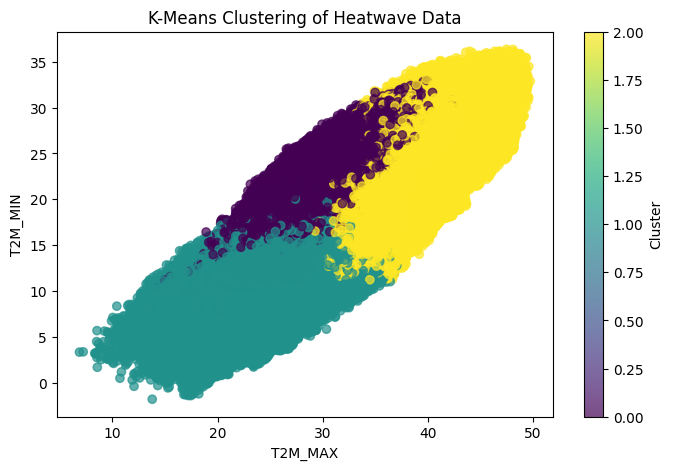

In [18]:
if len(selected_columns) >= 2:
    plt.figure(figsize=(8, 5))

    plt.scatter(
        data[selected_columns[0]],
        data[selected_columns[1]],
        c=cluster_labels,
        cmap="viridis",
        alpha=0.7
    )

    plt.xlabel(selected_columns[0])
    plt.ylabel(selected_columns[1])
    plt.title("K-Means Clustering of Heatwave Data")
    plt.colorbar(label="Cluster")
    plt.show()

In [19]:
consolidated_df.to_csv(
    "normalized_heatwave_data.csv", index=False
)

discretized_df.to_csv(
    "discretized_heatwave_data.csv", index=False
)

print("\nExperiment completed successfully!")
print("Saved: normalized_heatwave_data.csv")
print("Saved: discretized_heatwave_data.csv")

files.download("normalized_heatwave_data.csv")
files.download("discretized_heatwave_data.csv")



Experiment completed successfully!
Saved: normalized_heatwave_data.csv
Saved: discretized_heatwave_data.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>